# Titanic · исследование данных

Одна строка — пассажир; `Survived`: 0 — не выжил, 1 — выжил. Анализируем только размеченный `train.csv`.

**Содержание:** данные и target → пропуски → константы → корреляции → необычные значения → возраст → пол и класс → родственники → сведения о каюте → выводы.

Доли считаются внутри явно указанной группы. Связи в данных не доказывают причинность; EDA не измеряет прирост качества модели.

In [1]:
import os
import sys
from pathlib import Path

# Ядро может стартовать из корня проекта или из notebooks.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "config.yaml").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "config.yaml").is_file() or not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Откройте ноутбук из корня Titanic-ML или папки notebooks")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)  # Пути в конфиге и ячейках заданы от корня проекта.

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlepad": 16,
    "grid.alpha": 0.25,
})
pd.set_option("display.precision", 2)

main_color = "#287D8E"

## 1. Данные и целевая переменная

`PassengerId` — идентификатор; `Pclass`, `Sex`, `Embarked` — категории. `Age` и `Fare` — возраст и стоимость билета; `SibSp` и `Parch` — счётчики указанных родственников. Имена, билеты и каюты могут служить источниками новых признаков.

In [2]:
df = pd.read_csv("data/train.csv")
print(f"Пассажиров: {len(df)} · исходных колонок: {df.shape[1]}")
display(df.head(5))
target_summary = df.groupby("Survived").size().rename("Пассажиров").to_frame()
target_summary["Доля всех пассажиров, %"] = target_summary["Пассажиров"] / len(df) * 100
display(target_summary.rename(index={0: "Не выжили", 1: "Выжили"}))

Пассажиров: 891 · исходных колонок: 12


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.05,NaN,S


,Пассажиров,"Доля всех пассажиров, %"
Survived,,
Не выжили,549,61.62
Выжили,342,38.38


## 2. Пропуски

Сколько сведений отсутствует? Доли считаются среди всех 891 пассажира. Пропуск в `Cabin` означает отсутствие записи, а не отсутствие каюты.

In [3]:
missing_summary = pd.DataFrame({
    "Пропусков": df.isna().sum(),
    "Доля пропусков, %": df.isna().mean() * 100,
})
display(missing_summary.loc[missing_summary["Пропусков"] > 0].sort_values("Пропусков", ascending=False))

,Пропусков,"Доля пропусков, %"
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


Больше всего пропусков в `Cabin` (**77.10%**), затем в `Age` (**19.87%**); в `Embarked` — **0.22%**. В исследованных pipeline числа заполняются медианой train-фолда; категории обрабатываются согласно выбранной модели. Наличие записи каюты исследовано отдельно через `HasCabin`, сама колонка не используется в исходном наборе семи признаков.

## 3. Константные признаки

Проверяем исходные входы без target и ID. Константа имеет одно известное значение; полностью пустая колонка рассматривается отдельно. Колонка с одним известным значением и пропусками также требует проверки индикатора пропуска, а не автоматического удаления.

In [4]:
input_columns = df.columns.drop(["Survived", "PassengerId"])
unique_counts = df[input_columns].nunique(dropna=True)
constant_summary = pd.DataFrame({
    "Тип": df[input_columns].dtypes.astype(str),
    "Уникальных известных значений": unique_counts,
    "Проверка": np.where(unique_counts == 0, "Полностью пустая",
                         np.where(unique_counts == 1, "Один известный вариант", "Не константа")),
})
display(constant_summary)

,Тип,Уникальных известных значений,Проверка
Pclass,int64,3,Не константа
Name,str,891,Не константа
Sex,str,2,Не константа
Age,float64,88,Не константа
SibSp,int64,7,Не константа
Parch,int64,7,Не константа
Ticket,str,681,Не константа
Fare,float64,248,Не константа
Cabin,str,147,Не константа
Embarked,str,3,Не константа


**Результат:** среди десяти исходных входных колонок нет констант и полностью пустых колонок. По этой проверке ничего исключать не требуется. Уникальность ID и имён сама по себе не делает их подходящими входами модели.

## 4. Корреляции между числовыми входами

Pearson показывает линейную связь. `PassengerId`, target и категориальный `Pclass` в матрицу не включаем. Дополнительно показываем `FamilySize = SibSp + Parch + 1`, чтобы увидеть зависимость созданного признака от исходных. Это временная таблица для анализа, исходный `df` не меняется.

Пропуски не заполняем: для каждой пары используются строки, где известны оба значения. Для пар с `Age` это 714 пассажиров, для остальных — 891. Корреляция не обнаруживает все нелинейные и многомерные зависимости.

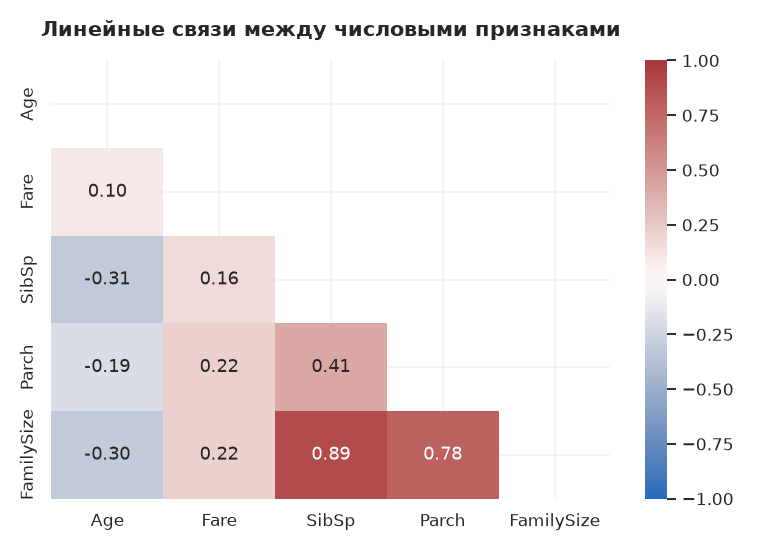

In [5]:
numeric_features = ["Age", "Fare", "SibSp", "Parch"]
correlation_data = df[numeric_features].assign(FamilySize=df["SibSp"] + df["Parch"] + 1)
correlations = correlation_data.corr(method="pearson")
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(correlations, mask=np.triu(np.ones_like(correlations, dtype=bool)),
            annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Линейные связи между числовыми признаками")
fig.tight_layout()
plt.show()

Среди четырёх исходных числовых входов максимальная абсолютная корреляция — **0.41** между `SibSp` и `Parch`; почти дублирующих линейных пар не обнаружено. `FamilySize` сильно связан с `SibSp` (**0.89**) и `Parch` (**0.78**) и точно вычисляется из них. Это повод учитывать повтор информации, но не автоматически удалять признаки. Наборы с добавлением и заменой исходных колонок уже проверялись в modeling.

## 5. Диапазоны и кандидаты в выбросы

Смотрим четыре числовых признака отдельно, без заполнения пропусков. IQR = Q3 − Q1; диагностические границы — Q1 − 1.5 × IQR и Q3 + 1.5 × IQR. Число за границами — сигнал для проверки, не список строк для удаления. Boxplot использует то же правило.

,Известных,Min,Q1,Медиана,Q3,P95,Max,Ниже 0,Вне IQR-границ
Признак,,,,,,,,,
Age,714,0.42,20.12,28.00,38.0,56.00,80.00,0,11
Fare,891,0.00,7.91,14.45,31.0,112.08,512.33,0,116
SibSp,891,0.00,0.00,0.00,1.0,3.00,8.00,0,46
Parch,891,0.00,0.00,0.00,0.0,2.00,6.00,0,213


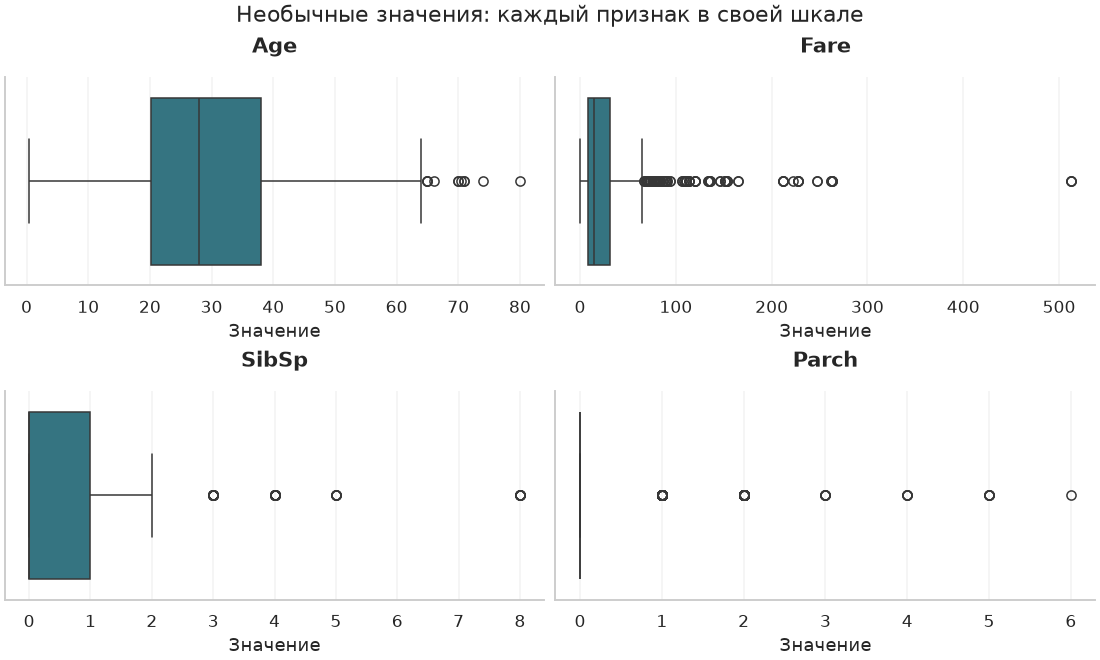

In [6]:
outlier_rows = []
for feature in numeric_features:
    values = df[feature].dropna()
    q1, median, q3, p95 = values.quantile([0.25, 0.5, 0.75, 0.95])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({
        "Признак": feature, "Известных": len(values), "Min": values.min(),
        "Q1": q1, "Медиана": median, "Q3": q3, "P95": p95, "Max": values.max(),
        "Ниже 0": int((values < 0).sum()),
        "Вне IQR-границ": int(((values < lower) | (values > upper)).sum()),
    })
outlier_summary = pd.DataFrame(outlier_rows).set_index("Признак")
display(outlier_summary.round(2))
fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
for ax, feature in zip(axes.flat, numeric_features):
    sns.boxplot(x=df[feature].dropna(), color=main_color, ax=ax)
    ax.set(title=feature, xlabel="Значение")
fig.suptitle("Необычные значения: каждый признак в своей шкале")
plt.show()

- `Age`: **0.42–80 лет**, отрицательных значений нет; 11 значений за IQR-границами. Это не доказывает ошибок в возрастах.
- `Fare`: **0–512.33**, 116 значений за IQR-границами. Большая стоимость и нулевая стоимость требуют контекста, а не автоматического удаления. `FareLog1p` уже исследован как преобразование масштаба.
- `SibSp`: **0–8**, 46 значений за границами; `Parch`: **0–6**, 213. Для дискретных счётчиков большие группы родственников могут быть корректны. У `Parch` Q1 = Q3 = 0: IQR-правило помечает любое положительное значение, поэтому здесь особенно мало подходит для удаления строк.

**Решение:** сохраняем строки и исходные значения; обнаруженных отрицательных значений нет. В этом блоке не вводим clipping или удаление выбросов. Если такая гипотеза появится, границы рассчитываются на train-фолде, а пользу проверяют по CV.

## 6. Возраст пассажиров

Гистограмма показывает форму распределения, а предыдущий boxplot — диапазон и редкие значения. Учитываются 714 известных возрастов; 177 пропусков не представлены.

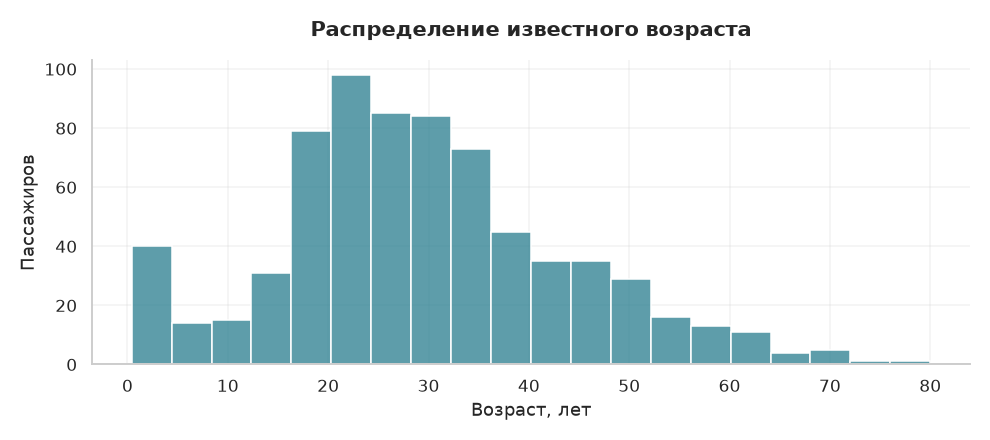

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x="Age", bins=20, color=main_color, edgecolor="white", ax=ax)
ax.set(title="Распределение известного возраста", xlabel="Возраст, лет", ylabel="Пассажиров")
fig.tight_layout()
plt.show()

Большинство известных возрастов сосредоточено в молодом и среднем взрослом возрасте; наблюдений в старших возрастах меньше. Форма гистограммы зависит от ширины интервалов.

## 7. Пол, класс билета и выживание

В таблицах доля выживших считается **среди пассажиров соответствующей группы**, а не среди всех выживших. Число наблюдений показано рядом. Совместная таблица помогает проверить различия между полами внутри классов.

In [8]:
for grouping in ["Sex", "Pclass", ["Pclass", "Sex"]]:
    survival = df.groupby(grouping)["Survived"].agg(Пассажиров="size", Выжили="sum")
    survival["Доля выживших внутри группы, %"] = survival["Выжили"] / survival["Пассажиров"] * 100
    display(survival.round(1))

,Пассажиров,Выжили,"Доля выживших внутри группы, %"
Sex,,,
female,314,233,74.2
male,577,109,18.9


,Пассажиров,Выжили,"Доля выживших внутри группы, %"
Pclass,,,
1,216,136,63.0
2,184,87,47.3
3,491,119,24.2


Пассажиров  Выжили  Доля выживших внутри группы, %
Pclass Sex                                                       
1      female          94      91                            96.8
       male           122      45                            36.9
2      female          76      70                            92.1
       male           108      17                            15.7
3      female         144      72                            50.0
       male           347      47                            13.5

Среди женщин выжили **74.2%**, среди мужчин — **18.9%**. В 1-м, 2-м и 3-м классах — **63.0%, 47.3%, 24.2%**. Различие между полами сохраняется внутри каждого класса. Это поддерживает проверку взаимодействия `SexPclass`, но не доказывает причинный эффект или прирост качества от нового признака.

## 8. Родственники на борту

Сумма `SibSp + Parch` не включает самого пассажира. Ноль означает отсутствие указанных родственников этих типов, а не доказательство путешествия без любых сопровождающих. Показываем размер каждой группы, чтобы не переоценивать редкие сочетания.

In [9]:
family_data = df.assign(Relatives=df["SibSp"] + df["Parch"])
family_summary = family_data.groupby("Relatives")["Survived"].agg(Пассажиров="size", Выжили="sum")
family_summary["Доля выживших внутри группы, %"] = family_summary["Выжили"] / family_summary["Пассажиров"] * 100
display(family_summary.round(1))

,Пассажиров,Выжили,"Доля выживших внутри группы, %"
Relatives,,,
0,537,163,30.4
1,161,89,55.3
2,102,59,57.8
3,29,21,72.4
4,15,3,20.0
5,22,3,13.6
6,12,4,33.3
7,6,0,0.0
10,7,0,0.0


У **60.3%** пассажиров сумма родственников равна нулю. Доля выживших не растёт монотонно с числом родственников; большие семьи представлены малыми группами. `FamilySize` и `IsAlone` уже проверены в моделях, их полезность зависит от конкретного pipeline.

## 9. Наличие записи каюты

`HasCabin=1` означает известную запись в `Cabin`, а не наличие каюты как таковой.

In [10]:
cabin_data = df.assign(HasCabin=df["Cabin"].notna().astype(int))
cabin_summary = cabin_data.groupby("HasCabin")["Survived"].agg(Пассажиров="size", Выжили="sum")
cabin_summary["Доля выживших внутри группы, %"] = cabin_summary["Выжили"] / cabin_summary["Пассажиров"] * 100
display(cabin_summary.rename(index={0: "Запись неизвестна", 1: "Запись известна"}).round(1))

,Пассажиров,Выжили,"Доля выживших внутри группы, %"
HasCabin,,,
Запись неизвестна,687,206,30.0
Запись известна,204,136,66.7


Запись известна у **204** пассажиров: среди них выжили **66.7%**; среди **687** пассажиров без записи — **30.0%**. Связь может отражать класс обслуживания и другие различия. Польза признака проверена отдельно в [modeling](modeling.ipynb): контрольная пара LightGBM дала 82.71% → 83.61% CV Accuracy; это результат конкретной модели, а не следствие самой таблицы EDA.

## 10. Итоги для подготовки данных

| Проверка | Результат | Решение |
|---|---|---|
| Константы и пустые колонки | Не найдены среди исходных входов | Ничего не исключаем по этому критерию |
| Корреляции | Нет почти дублирующих пар среди четырёх исходных числовых входов; `FamilySize` вычисляется из двух счётчиков | Не удаляем автоматически; состав признаков проверяем по CV |
| Необычные значения | Возраст и стоимость имеют крайние значения; IQR плохо подходит для разреженных счётчиков | Сохраняем строки; преобразования исследуем отдельно |
| Пропуски | Особенно много в `Cabin`, есть в `Age` и `Embarked` | Обработка зависит от модели и обучается на train-фолде |
| Групповые связи | Пол, класс, родственники и запись каюты связаны с target | Основания для гипотез, не доказательство причинности |

Результаты Feature Engineering и выбранные решения описаны в [журнале проекта](../KaggleTemplate.md).